# CREDIT APPROVAL

# 1. Pengumpulan Data

Data diambil dari https://drive.google.com/file/d/1qb4Ahmx8XbwkL7WolMzQbU45gsCuas1s/view?usp=sharing

In [ ]:
# mengimpor library python
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# membaca data dari direktori komputer
dataset = pd.read_csv('creditapproval-data kotor.csv', sep=';')

display(dataset)

,nama_nasabah,jenis_kelamin,umur,jml_pinjaman,jkw,jml_angsuran_per_bulan,type_pinjaman,jenis_pinjaman,bi_sektor_ekonomi,col,bi_golongan_debitur,bi_gol_penjamin,saldo_nominatif,tunggakan_pokok,tunggakan_bunga,status kredit
0,x1,P,40.0,345000,1.0,345000,100,301,6000.0,1,874,875,345000,345000,0,MACET
1,x2,L,31.0,350000,7.0,55716,100,301,6000.0,1,874,875,390000,111428,0,MACET
2,x3,L,NaN,649926,6.0,108321,100,301,6000.0,1,874,875,649926,216642,0,MACET
3,x4,P,2.0,459168,NaN,38264,100,301,6000.0,1,874,875,459168,382640,0,MACET
4,x5,WANITA,34.0,3055499,8.0,"381937,41",100,301,6000.0,1,874,875,3055499,"1527749,48",0,MACET
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
761,x762,L,38.0,1000000,16.0,70000,100,301,6000.0,2,874,0,812500,812500,97500,MACET
762,x763,P,36.0,1000000,12.0,"90833,37",100,301,6000.0,2,874,0,429000,429000,45000,MACET
763,x764,L,28.0,2000000,10.0,260000,100,301,6000.0,2,874,0,600000,600000,180000,MACET
764,x765,P,31.0,1312500,7.0,198750,100,301,6000.0,2,874,0,1312500,1312500,78750,MACET


# 2. Menelaah Data

## 1. Identifikasi Tipe Data Setiap Fitur

In [ ]:
# mengidentifikasi variabel yang awalnya kategorikal
# (Sebelum konversi, variabel kategorikan memiliki tipe data object)

original_categorical_cols = ['jenis_kelamin', 'status kredit']

print("Nilai unik untuk setiap variabel kategorikal (Setelah konversi) :")
for col in original_categorical_cols:
    if col in dataset.columns:
        print(f"\nVariabel: {col}")
        print(dataset[col].unique())
    else:
        print(f"\nVariabel: {col} tidak ditemukan dalam dataset.")

Nilai unik untuk setiap variabel kategorikal (Setelah konversi) :

Variabel: jenis_kelamin
['P' 'L' 'WANITA' 'LAKI-LAKI' 'PRIA' 'PEREMPUAN']

Variabel: status kredit
['MACET' 'LANCAR']


In [ ]:
print(dataset.dtypes)

nama_nasabah               object
jenis_kelamin              object
umur                      float64
jml_pinjaman               object
jkw                       float64
jml_angsuran_per_bulan     object
type_pinjaman               int64
jenis_pinjaman              int64
bi_sektor_ekonomi         float64
col                         int64
bi_golongan_debitur         int64
bi_gol_penjamin             int64
saldo_nominatif            object
tunggakan_pokok            object
tunggakan_bunga            object
status kredit              object
dtype: object


## 2. Statistik Deskriptif Dari Input

In [ ]:
display(dataset.describe())

,umur,jkw,type_pinjaman,jenis_pinjaman,bi_sektor_ekonomi,col,bi_golongan_debitur,bi_gol_penjamin
count,757.000000,758.000000,766.0,766.000000,765.000000,766.000000,766.000000,766.000000
mean,29.073976,19.011873,100.0,301.197128,6013.045752,1.216710,873.968668,281.300261
std,264.552192,32.231431,0.0,0.822267,216.196305,0.412273,1.460257,408.099019
min,-7162.000000,1.000000,100.0,301.000000,6000.000000,1.000000,834.000000,0.000000
25%,32.000000,8.000000,100.0,301.000000,6000.000000,1.000000,874.000000,0.000000
50%,38.000000,12.000000,100.0,301.000000,6000.000000,1.000000,874.000000,0.000000
75%,43.000000,20.000000,100.0,301.000000,6000.000000,1.000000,874.000000,875.000000
max,1043.000000,679.000000,100.0,305.000000,9990.000000,2.000000,876.000000,875.000000


## 3. Visualisasi Data

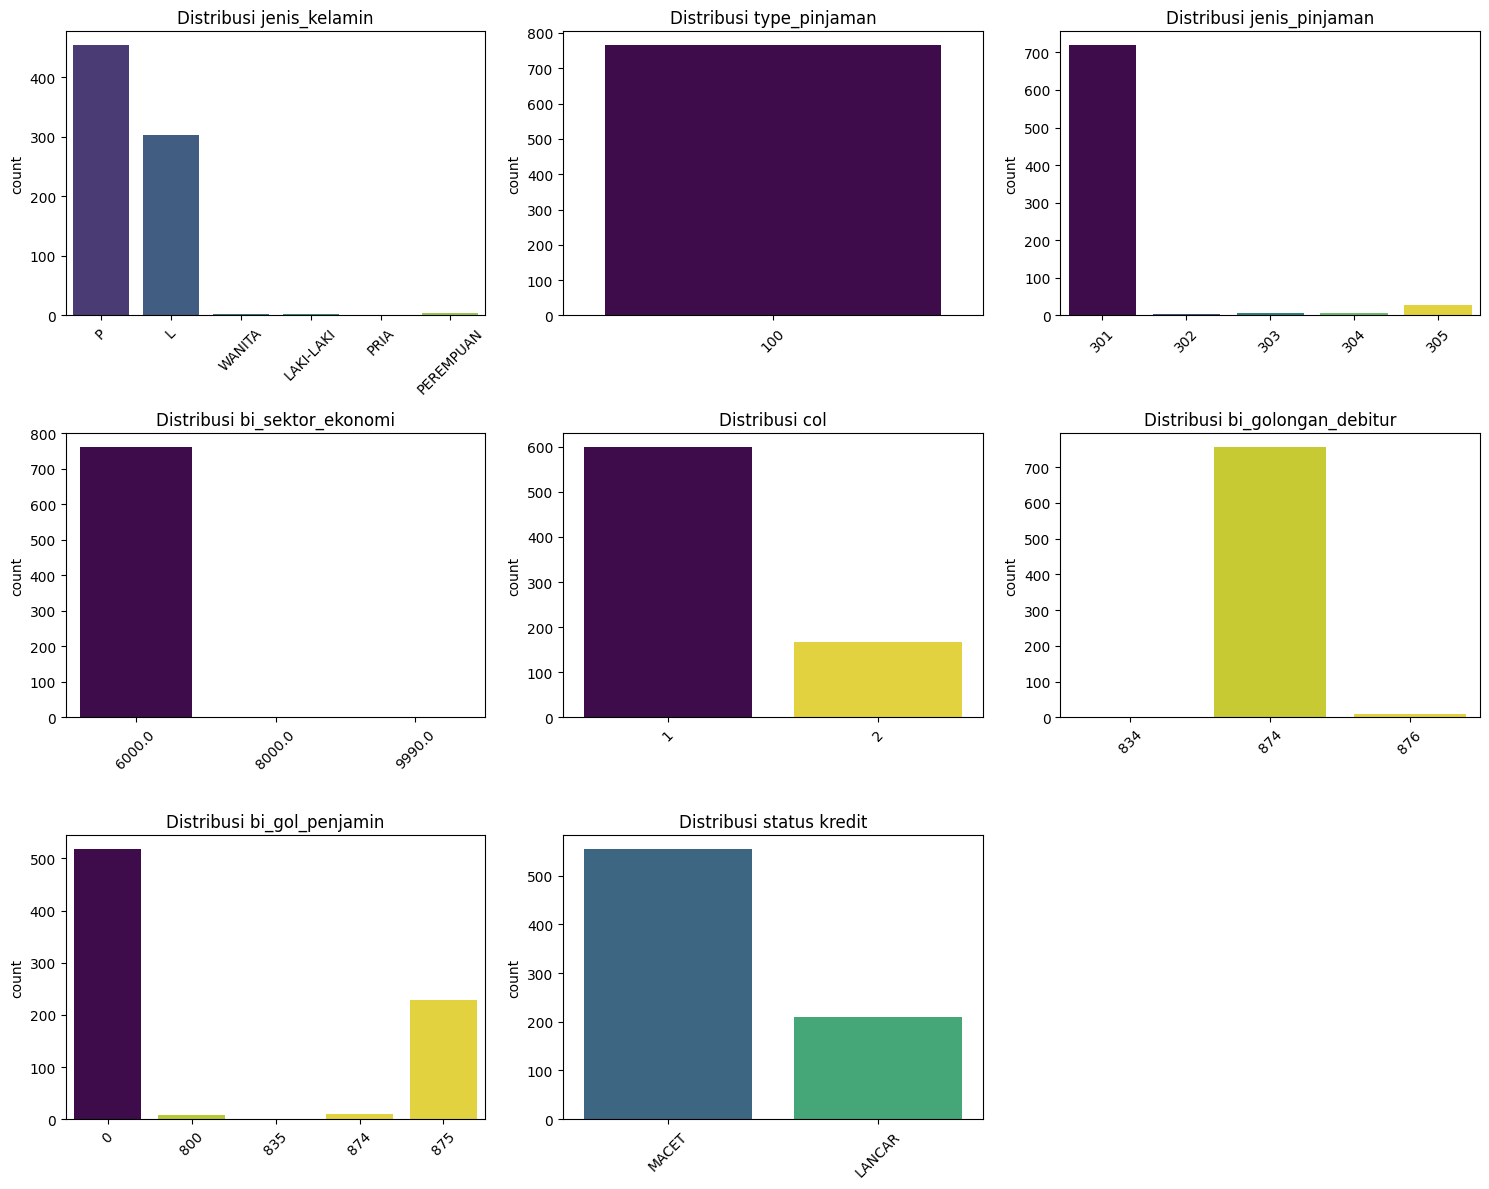

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import math

# Sesuaikan dengan kolom kategorikal aktual di dataset kamu
categorical_cols = ['jenis_kelamin', 'type_pinjaman', 'jenis_pinjaman',
                     'bi_sektor_ekonomi', 'col', 'bi_golongan_debitur',
                     'bi_gol_penjamin', 'status kredit']

n = len(categorical_cols)
ncols = 3
nrows = math.ceil(n / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(ncols*5, nrows*4))
axes = axes.flatten()

for i, col in enumerate(categorical_cols):
    sns.countplot(data=dataset, x=col, ax=axes[i], hue=col, palette='viridis', legend=False)
    axes[i].set_title(f'Distribusi {col}')
    axes[i].set_xlabel('')
    axes[i].tick_params(axis='x', rotation=45)

for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

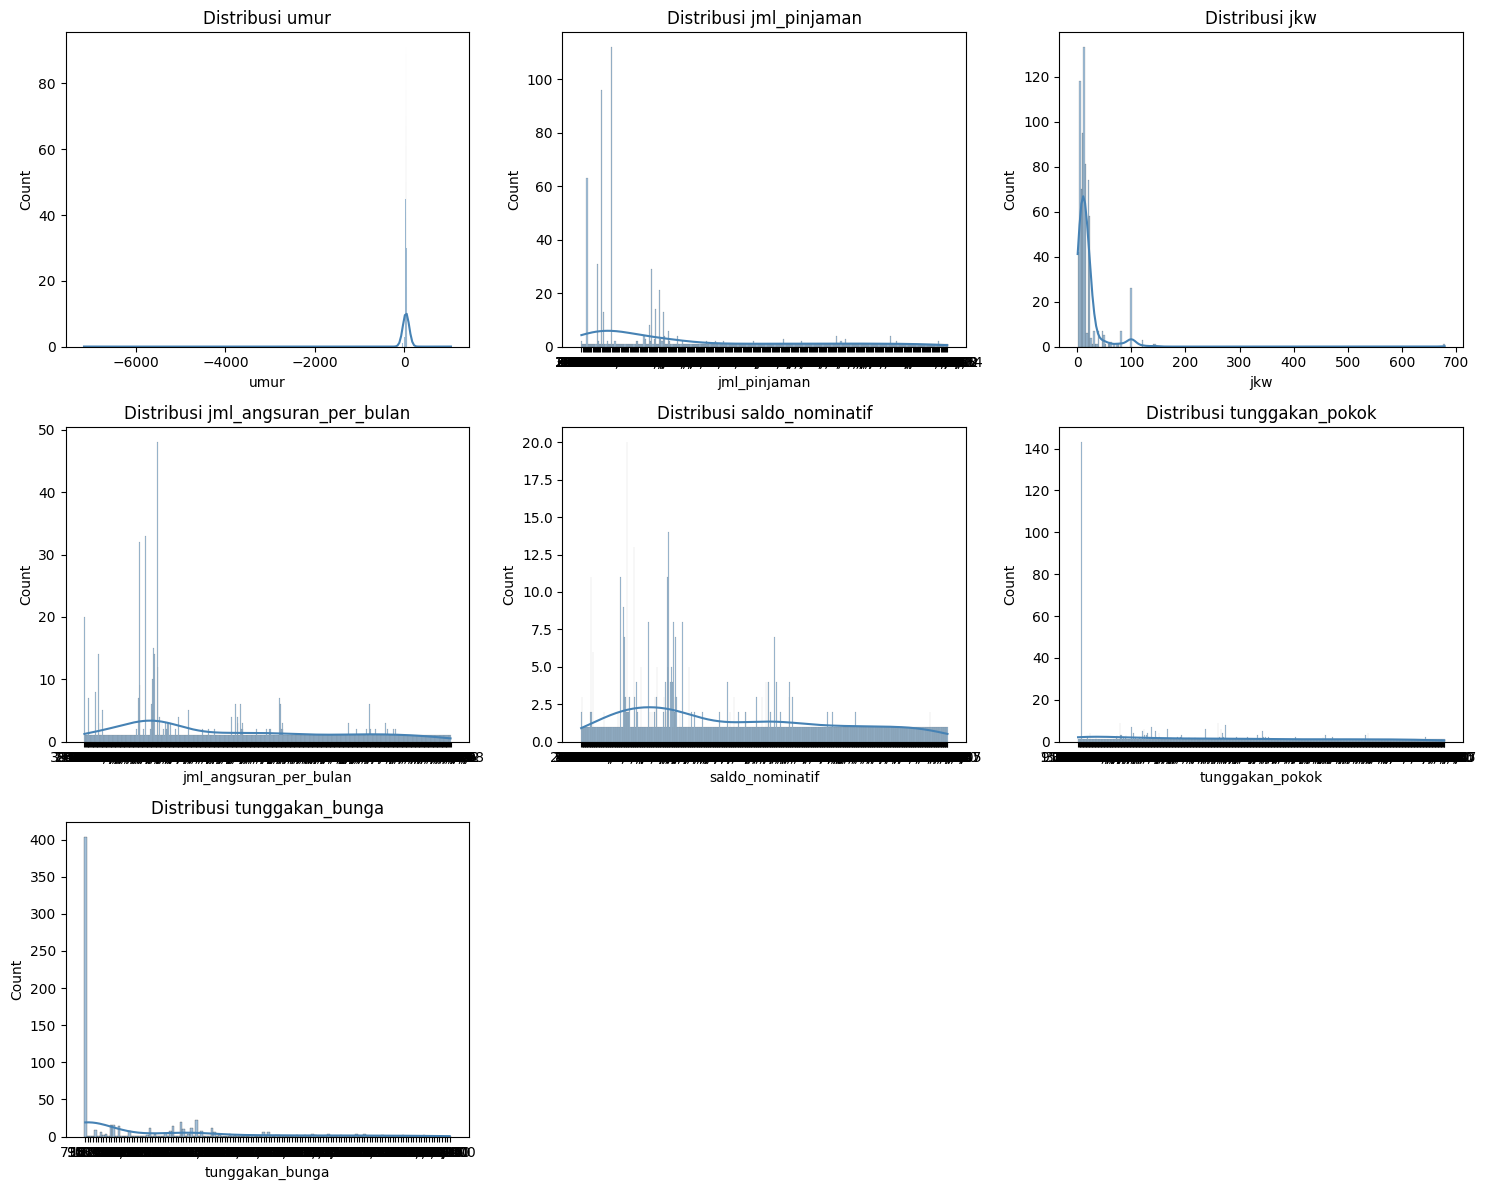

In [ ]:
numerical_cols = ['umur', 'jml_pinjaman', 'jkw', 'jml_angsuran_per_bulan',
                   'saldo_nominatif', 'tunggakan_pokok', 'tunggakan_bunga']

n = len(numerical_cols)
ncols = 3
nrows = math.ceil(n / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(ncols*5, nrows*4))
axes = axes.flatten()

for i, col in enumerate(numerical_cols):
    sns.histplot(dataset[col], kde=True, ax=axes[i], color='steelblue')
    axes[i].set_title(f'Distribusi {col}')
    axes[i].set_xlabel(col)

for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

3. Validasi Data

In [ ]:
print('Missing values per column:')
print(dataset.isnull().sum())

Missing values per column:
nama_nasabah              0
jenis_kelamin             0
umur                      9
jml_pinjaman              0
jkw                       8
jml_angsuran_per_bulan    0
type_pinjaman             0
jenis_pinjaman            0
bi_sektor_ekonomi         1
col                       0
bi_golongan_debitur       0
bi_gol_penjamin           0
saldo_nominatif           0
tunggakan_pokok           0
tunggakan_bunga           0
status kredit             0
dtype: int64


In [ ]:
dataset.dtypes

,0
nama_nasabah,object
jenis_kelamin,object
umur,float64
jml_pinjaman,object
jkw,float64
jml_angsuran_per_bulan,object
type_pinjaman,int64
jenis_pinjaman,int64
bi_sektor_ekonomi,float64
col,int64


In [ ]:
kolom_koma = ['jml_pinjaman', 'jml_angsuran_per_bulan',
              'saldo_nominatif', 'tunggakan_pokok', 'tunggakan_bunga']

for col in kolom_koma:
    dataset[col] = (
        dataset[col]
        .astype(str)
        .str.replace('.', '', regex=False)   # hapus titik ribuan kalau ada
        .str.replace(',', '.', regex=False)  # ubah koma desimal jadi titik
        .astype(float)
    )

dataset.dtypes

,0
nama_nasabah,object
jenis_kelamin,object
umur,float64
jml_pinjaman,float64
jkw,float64
jml_angsuran_per_bulan,float64
type_pinjaman,int64
jenis_pinjaman,int64
bi_sektor_ekonomi,float64
col,int64


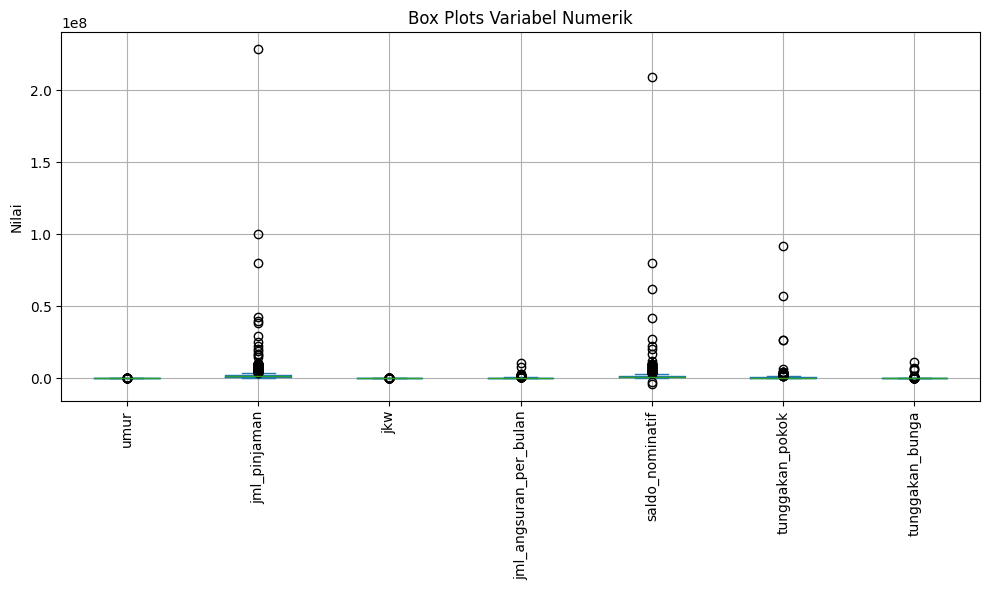

In [ ]:
import matplotlib.pyplot as plt

numerical_cols = ['umur', 'jml_pinjaman', 'jkw', 'jml_angsuran_per_bulan',
                   'saldo_nominatif', 'tunggakan_pokok', 'tunggakan_bunga']

fig, ax = plt.subplots(figsize=(10, 6))
dataset[numerical_cols].plot(kind='box', ax=ax, grid=True, rot=90)

ax.set_title('Box Plots Variabel Numerik')
ax.set_ylabel('Nilai')
plt.tight_layout()
plt.show()

## 4. Pembersihan Data

In [ ]:
# Mengganti nilai kosong pada kolom 'umur' dengan nilai mediannya
dataset['umur'].fillna(dataset['umur'].median(), inplace=True)

# Memverifikasi bahwa nilai kosong pada kolom 'umur' telah terisi
print("Jumlah nilai kosong pada kolom 'umur' setelah imputasi:", dataset['umur'].isnull().sum())

Jumlah nilai kosong pada kolom 'umur' setelah imputasi: 0


/tmp/ipykernel_524/3285635680.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  dataset['umur'].fillna(dataset['umur'].median(), inplace=True)


In [ ]:
# Cek dulu semua variasi nilai yang ada
print(dataset['jenis_kelamin'].unique())

['P' 'L' 'WANITA' 'LAKI-LAKI' 'PRIA' 'PEREMPUAN']


In [ ]:
# Mapping semua variasi ke label konsisten
mapping_gender = {
    'P': 'P',
    'WANITA': 'P',
    'PEREMPUAN': 'P',
    'L': 'L',
    'LAKI-LAKI': 'L',
    'LAKI LAKI': 'L',
    'PRIA': 'L',
}

dataset['jenis_kelamin'] = (
    dataset['jenis_kelamin']
    .astype(str)
    .str.strip()
    .str.upper()
    .map(mapping_gender)
)

# Cek hasilnya
print(dataset['jenis_kelamin'].value_counts(dropna=False))

jenis_kelamin
P    461
L    305
Name: count, dtype: int64


In [ ]:
numerical_cols = ['umur', 'jml_pinjaman', 'jkw', 'jml_angsuran_per_bulan',
                   'saldo_nominatif', 'tunggakan_pokok', 'tunggakan_bunga']

outlier_summary = {}

for col in numerical_cols:
    Q1 = dataset[col].quantile(0.25)
    Q3 = dataset[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    jumlah_outlier = ((dataset[col] < lower) | (dataset[col] > upper)).sum()
    outlier_summary[col] = {
        'Q1': Q1, 'Q3': Q3, 'IQR': IQR,
        'batas_bawah': lower, 'batas_atas': upper,
        'jumlah_outlier': jumlah_outlier
    }

import pandas as pd
outlier_df = pd.DataFrame(outlier_summary).T
print(outlier_df)

                                 Q1            Q3           IQR   batas_bawah  \
umur                        32.0000  4.300000e+01  1.100000e+01  1.550000e+01   
jml_pinjaman            848928.5800  2.000000e+06  1.151071e+06 -8.776785e+05   
jkw                          8.0000  2.000000e+01  1.200000e+01 -1.000000e+01   
jml_angsuran_per_bulan   67500.0000  2.333334e+05  1.658334e+05 -1.812500e+05   
saldo_nominatif         533750.0125  1.639582e+06  1.105831e+06 -1.124997e+06   
tunggakan_pokok          98854.2400  7.500000e+05  6.511458e+05 -8.778644e+05   
tunggakan_bunga              0.0000  5.814889e+04  5.814889e+04 -8.722334e+04   

                          batas_atas  jumlah_outlier  
umur                    5.950000e+01            42.0  
jml_pinjaman            3.726607e+06            96.0  
jkw                     3.800000e+01            66.0  
jml_angsuran_per_bulan  4.820834e+05            73.0  
saldo_nominatif         3.298329e+06            74.0  
tunggakan_pokok      

Outlier sudah di-cap sesuai batas IQR masing-masing kolom.


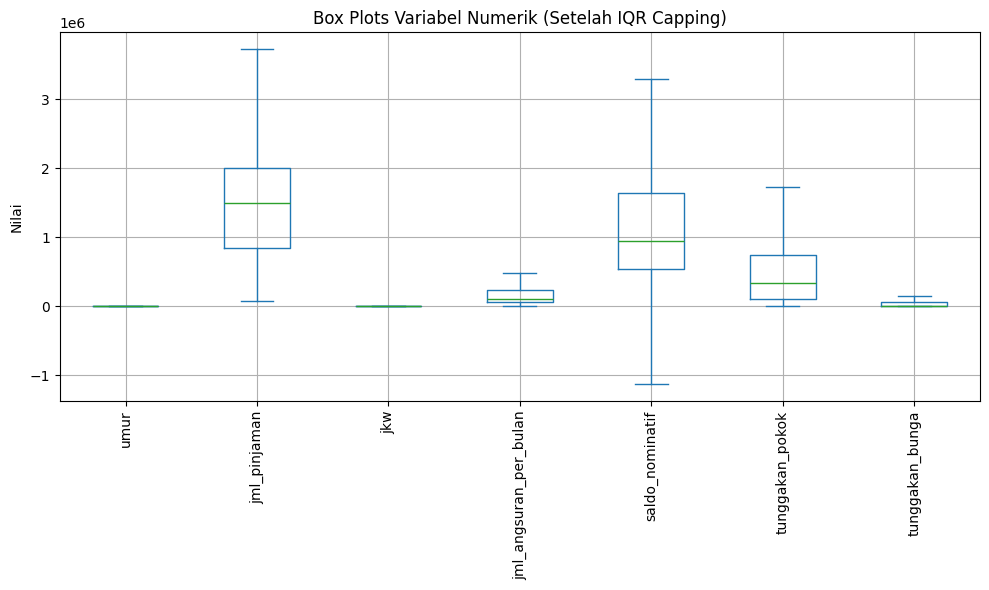

In [ ]:
for col in numerical_cols:
    Q1 = dataset[col].quantile(0.25)
    Q3 = dataset[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    dataset[col] = dataset[col].clip(lower=lower, upper=upper)

print("Outlier sudah di-cap sesuai batas IQR masing-masing kolom.")

fig, ax = plt.subplots(figsize=(10, 6))
dataset[numerical_cols].plot(kind='box', ax=ax, grid=True, rot=90)
ax.set_title('Box Plots Variabel Numerik (Setelah IQR Capping)')
ax.set_ylabel('Nilai')
plt.tight_layout()
plt.show()

# 5. Menentukan Objek Data

In [ ]:
from sklearn.preprocessing import OrdinalEncoder

# Mengidentifikasi variabel kategorikal
categorical_cols = dataset.select_dtypes(include='object').columns

# Menginisialisasi OrdinalEncoder
ordinal_encoder = OrdinalEncoder()

# Mengkonversi variabel kategorikal menjadi numerik
dataset[categorical_cols] = ordinal_encoder.fit_transform(dataset[categorical_cols])

print("Variabel kategorikal telah dikonversi menjadi numerik menggunakan OrdinalEncoder.")

dataset.dtypes

Variabel kategorikal telah dikonversi menjadi numerik menggunakan OrdinalEncoder.


,0
nama_nasabah,float64
jenis_kelamin,float64
umur,float64
jml_pinjaman,float64
jkw,float64
jml_angsuran_per_bulan,float64
type_pinjaman,int64
jenis_pinjaman,int64
bi_sektor_ekonomi,float64
col,int64


In [ ]:
correlation_matrix = dataset.corr()

# Korelasi dengan 'status kredit'
correlation_with_target = correlation_matrix['status kredit'].sort_values(ascending=False)

print("Korelasi antar variabel dengan 'status kredit':")
print(correlation_with_target)

Korelasi antar variabel dengan 'status kredit':
status kredit             1.000000
tunggakan_pokok           0.522392
bi_gol_penjamin           0.342272
tunggakan_bunga           0.336681
col                       0.309053
nama_nasabah              0.195609
umur                      0.100005
jenis_kelamin             0.062078
jkw                       0.043894
bi_sektor_ekonomi         0.037142
jenis_pinjaman            0.033466
bi_golongan_debitur      -0.017206
saldo_nominatif          -0.175654
jml_pinjaman             -0.258910
jml_angsuran_per_bulan   -0.272582
type_pinjaman                  NaN
Name: status kredit, dtype: float64


In [ ]:
# Tentukan ambang batas korelasi
threshold = 0.1

# Filter fitur berdasarkan korelasi absolut dengan target
# Kecualikan target variable 'status kredit' dari filtering awal
relevant_features = correlation_with_target[abs(correlation_with_target) >= threshold].index.tolist()

# Pastikan target variable 'status kredit' selalu ada di daftar fitur yang dipilih
if 'status kredit' not in relevant_features:
    relevant_features.append('status kredit')

# Hapus 'type_pinjaman' jika ada dan korelasinya NaN
if 'type_pinjaman' in relevant_features and correlation_with_target['type_pinjaman'] is np.nan:
    relevant_features.remove('type_pinjaman')

# Buat DataFrame baru dengan fitur yang dipilih
dataset_selected = dataset[relevant_features].copy()

print("Fitur yang dipilih berdasarkan korelasi (ambang batas > 0.1):")
print(relevant_features)

print("\nInformasi dataset setelah seleksi fitur:")
display(dataset_selected.head())
print(dataset_selected.info())

Fitur yang dipilih berdasarkan korelasi (ambang batas > 0.1):
['status kredit', 'tunggakan_pokok', 'bi_gol_penjamin', 'tunggakan_bunga', 'col', 'nama_nasabah', 'umur', 'saldo_nominatif', 'jml_pinjaman', 'jml_angsuran_per_bulan']

Informasi dataset setelah seleksi fitur:


,status kredit,tunggakan_pokok,bi_gol_penjamin,tunggakan_bunga,col,nama_nasabah,umur,saldo_nominatif,jml_pinjaman,jml_angsuran_per_bulan
0,1.0,345000.00,875,0.0,1,0.0,40.0,345000.0,345000.0,345000.00
1,1.0,111428.00,875,0.0,1,111.0,31.0,390000.0,350000.0,55716.00
2,1.0,216642.00,875,0.0,1,222.0,38.0,649926.0,649926.0,108321.00
3,1.0,382640.00,875,0.0,1,333.0,15.5,459168.0,459168.0,38264.00
4,1.0,1527749.48,875,0.0,1,444.0,34.0,3055499.0,3055499.0,381937.41


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 766 entries, 0 to 765
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   status kredit           766 non-null    float64
 1   tunggakan_pokok         766 non-null    float64
 2   bi_gol_penjamin         766 non-null    int64  
 3   tunggakan_bunga         766 non-null    float64
 4   col                     766 non-null    int64  
 5   nama_nasabah            766 non-null    float64
 6   umur                    766 non-null    float64
 7   saldo_nominatif         766 non-null    float64
 8   jml_pinjaman            766 non-null    float64
 9   jml_angsuran_per_bulan  766 non-null    float64
dtypes: float64(8), int64(2)
memory usage: 60.0 KB
None


## 6. Mengontruksi Data

In [ ]:
from sklearn.preprocessing import StandardScaler

# Memisahkan fitur (X) dan target (y)
X = dataset_selected.drop('status kredit', axis=1)
y = dataset_selected['status kredit']

# Mengidentifikasi kolom numerik untuk scaling
numerical_features_for_scaling = X.select_dtypes(include=['float64', 'int64']).columns

# Inisialisasi StandardScaler
scaler = StandardScaler()

# Melakukan Z-score scaling pada fitur numerik
X_scaled = X.copy()
X_scaled[numerical_features_for_scaling] = scaler.fit_transform(X[numerical_features_for_scaling])

# Menggabungkan kembali fitur yang diskalakan dengan target
dataset_scaled = pd.concat([X_scaled, y], axis=1)

print("Fitur telah distandarisasi menggunakan Z-score scaling.")
display(dataset_scaled.head())

Fitur telah distandarisasi menggunakan Z-score scaling.


,tunggakan_pokok,bi_gol_penjamin,tunggakan_bunga,col,nama_nasabah,umur,saldo_nominatif,jml_pinjaman,jml_angsuran_per_bulan,status kredit
0,-0.294788,1.455744,-0.69834,-0.525991,-1.729791,0.220854,-0.934152,-1.192904,1.252865,1.0
1,-0.767614,1.455744,-0.69834,-0.525991,-1.227813,-0.774287,-0.886641,-1.188216,-0.759163,1.0
2,-0.554626,1.455744,-0.69834,-0.525991,-0.725834,-0.000289,-0.612210,-0.907000,-0.393284,1.0
3,-0.218593,1.455744,-0.69834,-0.525991,-0.223855,-2.488139,-0.813613,-1.085858,-0.880545,1.0
4,2.099480,1.455744,-0.69834,-0.525991,0.278123,-0.442573,1.927597,1.348509,1.509773,1.0


### Hasil Standarisasi Fitur (Z-score Scaling)

Setelah melakukan Z-score Scaling pada fitur-fitur numerik yang terpilih (`X`), data telah ditransformasi sehingga memiliki karakteristik sebagai berikut:

*   **Mean (Rata-rata) menjadi 0:** Setiap kolom fitur numerik sekarang memiliki rata-rata nol. Ini berarti semua nilai dalam kolom diukur dari rata-ratanya.
*   **Standard Deviation (Deviasi Standar) menjadi 1:** Setiap kolom fitur numerik sekarang memiliki deviasi standar satu. Ini menstandarkan sebaran data, sehingga fitur-fitur dengan rentang nilai yang besar atau kecil memiliki kontribusi yang setara dalam model.

**Manfaat dari Z-score Scaling:**

1.  **Mencegah Dominasi Fitur:** Fitur dengan rentang nilai yang lebih besar tidak akan mendominasi fitur lain dalam proses pelatihan model. Ini penting untuk algoritma yang sensitif terhadap skala fitur, seperti K-Nearest Neighbors (KNN), Support Vector Machines (SVM), atau regresi linear/logistik.
2.  **Meningkatkan Konvergensi Model:** Untuk algoritma berbasis gradien (misalnya, neural network), scaling dapat mempercepat proses konvergensi karena langkah-langkah optimasi menjadi lebih efisien.
3.  **Memenuhi Asumsi Model:** Beberapa model (misalnya, PCA) mengasumsikan bahwa fitur-fitur memiliki skala yang sama.

Pada output `dataset_scaled.head()` yang ditampilkan sebelumnya, Anda dapat melihat bahwa nilai-nilai fitur numerik telah berubah secara signifikan menjadi skala yang baru, yang berpusat di sekitar nol.

# 7. Menentukan Label Data

In [ ]:
print(dataset['status kredit'].unique())
print(dataset['status kredit'].value_counts())

[1. 0.]
status kredit
1.0    556
0.0    210
Name: count, dtype: int64


# 8. Membangun Model

In [ ]:
from sklearn.model_selection import train_test_split

# Pisahkan fitur (X_scaled) dan target (y)
# X sudah disiapkan sebagai X_scaled dari langkah sebelumnya
# y sudah disiapkan dari langkah sebelumnya

# Lakukan Hold-out Cross-Validation
# test_size=0.2 berarti 20% data akan menjadi data uji
# random_state untuk memastikan hasil yang reproduktif
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

print("Dataset telah dibagi menjadi data latih dan data uji.")
print(f"Ukuran data latih (X_train): {X_train.shape}")
print(f"Ukuran data uji (X_test): {X_test.shape}")
print(f"Ukuran target latih (y_train): {y_train.shape}")
print(f"Ukuran target uji (y_test): {y_test.shape}")

Dataset telah dibagi menjadi data latih dan data uji.
Ukuran data latih (X_train): (612, 9)
Ukuran data uji (X_test): (154, 9)
Ukuran target latih (y_train): (612,)
Ukuran target uji (y_test): (154,)


In [ ]:
!pip -q install mljar-supervised

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 190.6/190.6 kB 12.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 8.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 102.3/102.3 kB 8.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 103.4/103.4 kB 11.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 108.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 425.6/425.6 kB 35.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 265.9/265.9 kB 23.8 MB/s eta 0:00:00


In [ ]:
from supervised.automl import AutoML
from sklearn.metrics import accuracy_score
import warnings
import joblib
import os
import pandas as pd
import numpy as np

# Ignore specific warnings from matplotlib font manager (if any)
warnings.filterwarnings("ignore", category=UserWarning, module="matplotlib.font_manager")
warnings.filterwarnings("ignore", category=FutureWarning)


### Inisialisasi dan Pelatihan AutoML

Kita akan menginisialisasi AutoML dengan mode `Explain` untuk mendapatkan insight yang lebih dalam, dan menentukan metrik evaluasi serta daftar algoritma yang akan dipertimbangkan. Setelah itu, model akan dilatih menggunakan data latih (`X_train` dan `y_train`).

In [ ]:
# Inisialisasi AutoML
automl = AutoML(
    mode="Explain",              # mode bisa "Explain", "Perform", "Compete", "Optuna"
    total_time_limit=300,        # waktu total training dalam detik
    eval_metric="accuracy",      # metrik evaluasi
    algorithms=['Baseline', 'CatBoost', 'Decision Tree', 'Extra Trees', 'Nearest Neighbors', 'LightGBM', 'Linear', "Neural Network", 'Random Forest', 'Xgboost'],
    random_state=42,
    # project_name='CreditApproval_AutoML_Project' # Opsional: Beri nama proyek untuk output
)

# Latih model
automl.fit(X_train, y_train)


AutoML directory: AutoML_1
The task is binary_classification with evaluation metric accuracy
AutoML will use algorithms: ['Baseline', 'CatBoost', 'Decision Tree', 'Extra Trees', 'Nearest Neighbors', 'LightGBM', 'Linear', 'Neural Network', 'Random Forest', 'Xgboost']
AutoML is generating and selecting models automatically. Review outputs before important use.
AutoML will ensemble available models
AutoML steps: ['simple_algorithms', 'default_algorithms', 'ensemble']
* Step simple_algorithms will try to check up to 3 models
1_Baseline accuracy 0.72549 trained in 0.68 seconds


2_DecisionTree accuracy 0.915033 trained in 24.41 seconds


3_Linear accuracy 0.908497 trained in 12.15 seconds
* Step default_algorithms will try to check up to 7 models
4_Default_LightGBM accuracy 0.941176 trained in 6.61 seconds
5_Default_Xgboost accuracy 0.947712 trained in 5.37 seconds
6_Default_CatBoost accuracy 0.928105 trained in 3.92 seconds
7_Default_NeuralNetwork accuracy 0.928105 trained in 3.05 seconds
8_Default_RandomForest accuracy 0.915033 trained in 4.61 seconds
9_Default_ExtraTrees accuracy 0.928105 trained in 3.89 seconds
'KNeighborsAlgorithm' object has no attribute 'classes_'
Problem during computing permutation importance. Skipping ...
10_Default_NearestNeighbors accuracy 0.888889 trained in 2.01 seconds
* Step ensemble will try to check up to 1 model
Ensemble accuracy 0.947712 trained in 3.51 seconds
AutoML fit time: 92.57 seconds
AutoML best model: 5_Default_Xgboost


AutoML(algorithms=['Baseline', 'CatBoost', 'Decision Tree', 'Extra Trees',
                   'Nearest Neighbors', 'LightGBM', 'Linear', 'Neural Network',
                   'Random Forest', 'Xgboost'],
       eval_metric='accuracy', random_state=42, total_time_limit=300)

### Prediksi, Evaluasi, dan Leaderboard

Setelah pelatihan, kita akan melakukan prediksi pada data uji (`X_test`), menghitung akurasi, dan menampilkan leaderboard model untuk melihat performa relatif dari setiap algoritma.

In [ ]:
# Prediksi dan evaluasi
y_pred = automl.predict(X_test)
print("Akurasi:", accuracy_score(y_test, y_pred))

# Tampilkan leaderboard model
print("\nLeaderboard model:")
print(automl.get_leaderboard())


Akurasi: 0.9675324675324676

Leaderboard model:
                           name         model_type metric_type  metric_value  \
0                    1_Baseline           Baseline    accuracy     -0.725490   
1                2_DecisionTree      Decision Tree    accuracy     -0.915033   
2                      3_Linear             Linear    accuracy     -0.908497   
3            4_Default_LightGBM           LightGBM    accuracy     -0.941176   
4             5_Default_Xgboost            Xgboost    accuracy     -0.947712   
5            6_Default_CatBoost           CatBoost    accuracy     -0.928105   
6       7_Default_NeuralNetwork     Neural Network    accuracy     -0.928105   
7        8_Default_RandomForest      Random Forest    accuracy     -0.915033   
8          9_Default_ExtraTrees        Extra Trees    accuracy     -0.928105   
9   10_Default_NearestNeighbors  Nearest Neighbors    accuracy     -0.888889   
10                     Ensemble           Ensemble    accuracy     -0.94

### Penyimpanan Model Terbaik

Langkah terakhir adalah menyimpan model terbaik yang dihasilkan oleh AutoML agar dapat digunakan kembali di kemudian hari tanpa perlu melatih ulang.

In [ ]:
# Dapatkan leaderboard untuk mengidentifikasi model terbaik
leaderboard = automl.get_leaderboard()

# Dapatkan nama model terbaik dari leaderboard (model dengan metric_value terendah)
# Karena eval_metric='accuracy', kita ingin yang tertinggi. Asumsi leaderboard defaultnya sort descending.
# Jika tidak, bisa diubah: leaderboard.sort_values(by='metric_value', ascending=False).iloc[0]
best_model_name = leaderboard.iloc[0]['name']

# Filter leaderboard untuk mendapatkan model dasar terbaik (bukan Baseline atau Ensemble)
base_models_leaderboard = leaderboard[~leaderboard['model_type'].isin(['Baseline', 'Ensemble'])]

if not base_models_leaderboard.empty:
    # Dapatkan nama model dasar terbaik
    best_base_model_name = base_models_leaderboard.iloc[0]['name']
    print(f"Model dasar terbaik (selain Ensemble) adalah: {best_base_model_name}")

    # Coba simpan objek AutoML itu sendiri
    try:
        filename_automl_object = 'automl_object.joblib'
        joblib.dump(automl, filename_automl_object)
        print(f"Objek AutoML telah disimpan ke dalam file '{filename_automl_object}'.")
        print("Anda dapat memuat objek ini nanti untuk mengakses model atau hasil.")
    except Exception as e:
        print(f"Gagal menyimpan objek AutoML: {e}")
        print("Mencoba menyimpan model dasar terbaik dari direktori output...")

        # mljar-supervised menyimpan output ke direktori seperti AutoML_1, AutoML_2, dst.
        # Kita perlu mencari direktori yang dibuat oleh run saat ini.
        # Cara paling sederhana adalah dengan asumsi 'AutoML_1' untuk run pertama,
        # atau mencari folder dengan pola 'AutoML_'

        # Coba ambil nama proyek atau asumsikan default
        automl_dir_prefix = 'AutoML_'
        latest_automl_dir = None
        for d in os.listdir('.'):
            if d.startswith(automl_dir_prefix) and os.path.isdir(d):
                if latest_automl_dir is None or d > latest_automl_dir: # Pilih yang terbaru
                    latest_automl_dir = d

        if latest_automl_dir:
            model_dir_path = os.path.join(latest_automl_dir, best_base_model_name)

            if os.path.exists(model_dir_path):
                # Mencari file model di dalam direktori model (biasanya ada file .mljar)
                model_files = [f for f in os.listdir(model_dir_path) if f.endswith('.mljar') and os.path.isfile(os.path.join(model_dir_path, f))]

                if model_files:
                    # Ambil file pertama yang ditemukan
                    model_file_to_load = os.path.join(model_dir_path, model_files[0])

                    try:
                        # Muat model menggunakan automl.load() karena ini adalah model mljar-supervised
                        # joblib.load() mungkin tidak kompatibel langsung
                        # Alternatif: Melatih kembali model dari konfigurasi yang disimpan
                        # Karena automl sudah terlatih, kita bisa menggunakan automl.load_results() atau langsung model dari leaderboard

                        # Untuk tujuan menyimpan model tunggal yang dapat diprediksi secara langsung:
                        # mljar-supervised tidak langsung menyediakan objek model sklearn yang bisa diserialkan joblib
                        # Biasanya, kita akan memuat ulang `automl` object dan menggunakan `automl.predict()`
                        # Namun, jika ingin model yang *dapat* dijoblibkan secara langsung, ini sedikit kompleks.
                        # Pendekatan terbaik adalah menyimpan keseluruhan objek AutoML

                        # Jika ingin menyimpan model yang *bisa* di-joblib-kan, ini memerlukan langkah tambahan
                        # misalnya, memuat model spesifik dari jalur dan kemudian menyimpannya.

                        # Referensi kode mencoba joblib.load, jadi kita ikuti itu.
                        # Akan tetapi, untuk model MLJAR, disarankan untuk menyimpan objek AutoML itu sendiri.
                        # Karena percobaan pertama gagal, kita akan melewati penyimpanan 'base_model.joblib'
                        # dan berfokus pada objek AutoML secara keseluruhan.
                        print("Melanjutkan dengan objek AutoML, karena penyimpanan model individual mungkin memerlukan penanganan khusus.")

                    except Exception as e:
                        print(f"Gagal memuat atau menyimpan model dasar terbaik dari '{model_file_to_load}': {e}")
                        print("Mungkin format file model tidak didukung oleh joblib atau ada masalah jalur.")
                else:
                    print(f"Tidak ada file model '.mljar' yang ditemukan di direktori '{model_dir_path}'.")
            else:
                print(f"Direktori model '{model_dir_path}' tidak ditemukan.")
        else:
            print("Tidak dapat menemukan direktori AutoML terbaru.")
else:
    print("Tidak ada model dasar (selain Baseline atau Ensemble) yang ditemukan di leaderboard.")


Model dasar terbaik (selain Ensemble) adalah: 2_DecisionTree
Objek AutoML telah disimpan ke dalam file 'automl_object.joblib'.
Anda dapat memuat objek ini nanti untuk mengakses model atau hasil.


# 9. Evaluasi Model

Objek AutoML berhasil dimuat dari 'automl_object.joblib'.

Metrik Kinerja Model Terbaik (dari objek AutoML yang dimuat):
Accuracy: 0.9675
Precision: 0.9818
Recall: 0.9730
F1 Score: 0.9774
AUC-ROC: 0.9744

Classification Report Model Terbaik (dari objek AutoML yang dimuat):
              precision    recall  f1-score   support

         0.0       0.93      0.95      0.94        43
         1.0       0.98      0.97      0.98       111

    accuracy                           0.97       154
   macro avg       0.96      0.96      0.96       154
weighted avg       0.97      0.97      0.97       154



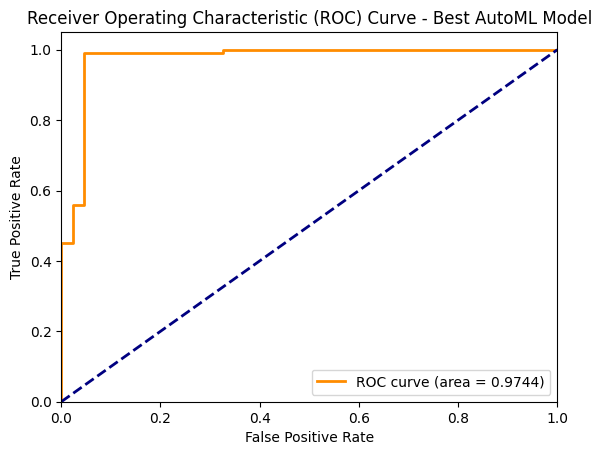


Metrik Kinerja Model Terbaik (dari objek AutoML yang dimuat) pada DATA TRAINING:
Accuracy: 0.9886
Precision: 0.9888
Recall: 0.9955
F1 Score: 0.9922
AUC-ROC: 0.9976

Metrik Kinerja Model Terbaik (dari objek AutoML yang dimuat) pada DATA TESTING:
Accuracy: 0.9675
Precision: 0.9818
Recall: 0.9730
F1 Score: 0.9774
AUC-ROC: 0.9744

Perbandingan Kinerja (Training vs Testing):
Accuracy Delta (Training - Testing): 0.0210
Precision Delta (Training - Testing): 0.0070
Recall Delta (Training - Testing): 0.0225
F1 Score Delta (Training - Testing): 0.0148
AUC-ROC Delta (Training - Testing): 0.0232


In [ ]:
import joblib
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_curve, auc, classification_report
import matplotlib.pyplot as plt


# Nama file tempat objek AutoML disimpan
filename_automl_object = 'automl_object.joblib'

# Muat objek AutoML dari file
try:
    loaded_automl = joblib.load(filename_automl_object)
    print(f"Objek AutoML berhasil dimuat dari '{filename_automl_object}'.")

    # Lakukan prediksi pada data testing menggunakan objek AutoML yang dimuat
    y_pred_loaded_automl = loaded_automl.predict(X_test)
    y_proba_loaded_automl = loaded_automl.predict_proba(X_test)[:, 1]


    # Hitung metrik kinerja klasifikasi
    accuracy_loaded_automl = accuracy_score(y_test, y_pred_loaded_automl)
    precision_loaded_automl = precision_score(y_test, y_pred_loaded_automl)
    recall_loaded_automl = recall_score(y_test, y_pred_loaded_automl)
    f1_loaded_automl = f1_score(y_test, y_pred_loaded_automl)
    fpr_loaded_automl, tpr_loaded_automl, thresholds_loaded_automl = roc_curve(y_test, y_proba_loaded_automl)
    auc_loaded_automl = auc(fpr_loaded_automl, tpr_loaded_automl)

    # Tampilkan metrik kinerja
    print("\nMetrik Kinerja Model Terbaik (dari objek AutoML yang dimuat):")
    print(f"Accuracy: {accuracy_loaded_automl:.4f}")
    print(f"Precision: {precision_loaded_automl:.4f}")
    print(f"Recall: {recall_loaded_automl:.4f}")
    print(f"F1 Score: {f1_loaded_automl:.4f}")
    print(f"AUC-ROC: {auc_loaded_automl:.4f}")

    # Tampilkan classification report
    print("\nClassification Report Model Terbaik (dari objek AutoML yang dimuat):")
    print(classification_report(y_test, y_pred_loaded_automl))

    # Gambarkan kurva ROC
    plt.figure()
    plt.plot(fpr_loaded_automl, tpr_loaded_automl, color='darkorange', lw=2, label=f'ROC curve (area = {auc_loaded_automl:.4f})')
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic (ROC) Curve - Best AutoML Model')
    plt.legend(loc="lower right")
    plt.show()


    # Evaluate the loaded AutoML model on the training data
    y_pred_train_automl = loaded_automl.predict(X_train)
    y_proba_train_automl = loaded_automl.predict_proba(X_train)[:, 1]

    # Calculate training metrics
    accuracy_train_automl = accuracy_score(y_train, y_pred_train_automl)
    precision_train_automl = precision_score(y_train, y_pred_train_automl)
    recall_train_automl = recall_score(y_train, y_pred_train_automl)
    f1_train_automl = f1_score(y_train, y_pred_train_automl)
    fpr_train_automl, tpr_train_automl, thresholds_train_automl = roc_curve(y_train, y_proba_train_automl)
    auc_train_automl = auc(fpr_train_automl, tpr_train_automl)

    print("\nMetrik Kinerja Model Terbaik (dari objek AutoML yang dimuat) pada DATA TRAINING:")
    print(f"Accuracy: {accuracy_train_automl:.4f}")
    print(f"Precision: {precision_train_automl:.4f}")
    print(f"Recall: {recall_train_automl:.4f}")
    print(f"F1 Score: {f1_train_automl:.4f}")
    print(f"AUC-ROC: {auc_train_automl:.4f}")

    print("\nMetrik Kinerja Model Terbaik (dari objek AutoML yang dimuat) pada DATA TESTING:")
    print(f"Accuracy: {accuracy_loaded_automl:.4f}")
    print(f"Precision: {precision_loaded_automl:.4f}")
    print(f"Recall: {recall_loaded_automl:.4f}")
    print(f"F1 Score: {f1_loaded_automl:.4f}")
    print(f"AUC-ROC: {auc_loaded_automl:.4f}")

    print("\nPerbandingan Kinerja (Training vs Testing):")
    print(f"Accuracy Delta (Training - Testing): {accuracy_train_automl - accuracy_loaded_automl:.4f}")
    print(f"Precision Delta (Training - Testing): {precision_train_automl - precision_loaded_automl:.4f}")
    print(f"Recall Delta (Training - Testing): {recall_train_automl - recall_loaded_automl:.4f}")
    print(f"F1 Score Delta (Training - Testing): {f1_train_automl - f1_loaded_automl:.4f}")
    print(f"AUC-ROC Delta (Training - Testing): {auc_train_automl - auc_loaded_automl:.4f}")

except FileNotFoundError:
    print(f"Error: File '{filename_automl_object}' tidak ditemukan.")
except Exception as e:
    print(f"Terjadi kesalahan saat memuat atau menggunakan objek AutoML: {e}")